<center><img src="https://images.pexels.com/photos/6280594/pexels-photo-6280594.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2" width="800" height="500"></center>

<b><h2><center>Bike Sharing Case Study</center></h2></b>

## **Problem Statement**

### **Context:**

Bike-sharing systems are a new generation of traditional bike rentals where the whole process from membership, rental and return back has become automatic. Through these systems, the user is able to easily rent a bike from a particular position and return back to another position. Currently, there are about over 500 bike-sharing programs around the world which are composed of over 500 thousand bicycles. Today, there exists a great interest in these systems due to their important role in traffic, environmental, and health issues.


### **Objective:**
'Travel Along' is a new bike-sharing company and wants to expand its customer count and provide better services at a reasonable cost. They have conducted several surveys and collated the data about weather, weekends, holidays, etc. from the past 2 years.

As a recently hired data scientist at 'travel along', you have been asked to analyze the patterns in the data and figure out the key areas which can help the organization to grow and manage the customer demands. Further, you need to use this information to predict the count of bikes shared so that the company can take prior decisions for surge hours.
- What are the different factors which affect the target variable? What business recommendations can we give based on the analysis?
- How can we use different ensemble techniques - Bagging, Boosting, and Stacking to build a model to predict the count of bikes rented?

### **Data Description:**

The bike-sharing rental process is highly correlated to the environmental and seasonal settings. For instance, weather conditions, precipitation, the day of week, season, the hour of the day, etc. can affect the rental behaviors.

- instant: record index
- dteday : date
- season : season (1:spring, 2:summer, 3:fall, 4:winter)
- yr : year (0: 2011, 1:2012)
- mnth : month ( 1 to 12)
- hr : hour (0 to 23)
- holiday : whether the day is holiday or not
- weekday : day of the week
- workingday : if the day is neither weekend nor holiday then 1, otherwise is 0.
- weathersit :
 - 1: Clear, Few clouds, Partly cloudy
 - 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
 - 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
 - 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
- temp : Normalized temperature in Celsius. The values are divided to 41 (max)
- atemp: Normalized feeling temperature in Celsius. The values are divided to 50 (max). The “feel like” temperature relies on environmental data including the ambient air temperature, relative humidity, and wind speed to determine how weather conditions feel to bare skin.
- hum: Normalized humidity. The values are divided to 100 (max)
windspeed: Normalized wind speed. The values are divided to 67 (max)
- casual: count of casual users
registered: count of registered users
cnt: count of total rental bikes including both casual and registered


## **1. Importing Necessary Libraries**

### **Let's import the required libraries for data `handling`, `visualization`, and `modeling`**

In [16]:
# 1. Data Processing & Math
import numpy as np
import pandas as pd

# 2. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Data Splitting & Hyperparameter Tunning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 4. Base Tree Algorithm
from sklearn.tree import DecisionTreeRegressor

# 5. Ensemble Learning: Bagging & Boosting Models
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor)
from xgboost import XGBRFRegressor

# 6. Model Evaluation Metrics
from sklearn import metrics

# 7. System & Warning Control
import warnings
warnings.filterwarnings("ignore")

# 8. Mount the google Drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Data Ingestion**
#### **Let's fetch the bike sharing records and check the dataset preview.**

In [17]:
# Loading dataset
df_hour = pd.read_csv("/content/drive/MyDrive/Dataset/hour.csv")

## **Overview of the dataset**

### Preview the first few records

In [ ]:
df_hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## **Check feature data types and identify missing values**

In [ ]:
df_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


- We can see that there are total of 17 columns and 17,379 rows in the dataset.
- All columns data type is either integer or float except one column - `dteday` which is of the object type.
- The number of non-null values of each column is equal to the number of total rows in the dataset i.e. no null value. We can further confirm this using `isna()` method.

In [ ]:
df_hour.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


- There are no missing values in the data.

## **Summary of the dataset**

In [ ]:
# summary of continuous columns
df_hour[["temp", "atemp", "hum", "windspeed", "cnt"]].describe().T

,count,mean,std,min,25%,50%,75%,max
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000
atemp,17379.0,0.475775,0.171850,0.00,0.3333,0.4848,0.6212,1.0000
hum,17379.0,0.627229,0.192930,0.00,0.4800,0.6300,0.7800,1.0000
windspeed,17379.0,0.190098,0.122340,0.00,0.1045,0.1940,0.2537,0.8507
cnt,17379.0,189.463088,181.387599,1.00,40.0000,142.0000,281.0000,977.0000


- The mean and median value of temperature is approx 0.50
- The mean and median value for 'atemp' is approx 0.47 and 0.48 respectively
- The mean and median value for 'hum' is approx 0.627 and 0.63 respectively
- Wind speed has some extreme values at the right end
- The target variable seems to have skewed distribution as higher values are on the right. We will explore this further.

## **Number of unique values in each column**

In [ ]:
df_hour.nunique()

,0
instant,17379
dteday,731
season,4
yr,2
mnth,12
hr,24
holiday,2
weekday,7
workingday,2
weathersit,4


- We can drop 'instant' column as it is an ID variable and will not add value to the model.
- We can drop 'dteday' column as it just contains dates of 731 days i.e. 2 years. This will not add value to the model.

In [18]:
# Dropping two columns from the dataframe
df_hour.drop(columns = ["instant", "dteday"], inplace = True)

## **Number of observations in each category**

In [ ]:
cat_cols = ["season", "yr", "holiday", "workingday", "weathersit"]

for column in cat_cols:
  print(df_hour[column].value_counts())
  print("="*30)

season
3    4496
2    4409
1    4242
4    4232
Name: count, dtype: int64
yr
1    8734
0    8645
Name: count, dtype: int64
holiday
0    16879
1      500
Name: count, dtype: int64
workingday
1    11865
0     5514
Name: count, dtype: int64
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


- The number of observations from year 0 i.e. 2011 is slightly more than the number of observations from year 1 i.e. 2012.
- As expected, the number of non-holidays and working days are much higher than the number of holidays and non-working days respectively.
- We have only 3 observations where weathersit=4 and most common is 1 i.e. clear or partly cloudy.

In [19]:
df = df_hour.copy()

## **📈 Exploratory Data Analysis (EDA) Summary**

### **Note**: The EDA section has been covered multiple times in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA. The detailed EDA can be found in the <a href = #link1>appendix section</a>.

### **The below functions need to be defined to carry out the EDA.**

In [ ]:
def histogram_boxplot(data, feature, figsize=(15, 8), kde=False, bins="auto"):
  """
  Boxplot and histogram combined for a dataset column.
  """

  # Create figure and 2 subplots
  fig, (ax_box, ax_hist) = plt.subplots(
      nrows = 2,
      sharex = True,
      gridspec_kw = {"height_ratios":(0.25, 0.75)},
      figsize = figsize)

  # Create the Boxplot showing the mean with a violet indicator
  sns.boxplot(data=data, x=feature, ax=ax_box, showmeans=True, color="violet")

  # Create the Histogram
  sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist, bins=bins, )

  # Calculate Mean and Median values
  mean_val = df[feature].mean()
  median_val = df[feature].median()

  # Add Mean and Median vertical lines to the Histogram
  ax_hist.axvline(mean_val, color="green", linestyle="--", label="Mean")
  ax_hist.axvline(median_val, color="black", linestyle="-", label="Median")

  # Add legend and display the plot
  ax_hist.legend()
  plt.show()

In [ ]:
def labeled_barplot(data, feature, perc=False, n=None):
  """
  Barplot for a categorical column, displaying Count
  or Parcentage at the top.
  """
  # Total number of rows in the column
  total = len(data[feature])

  # 1. Figure Size Logic
  num_categories = data[feature].nunique() if n is None else n
  plt.figure(figsize=(num_categories + 2, 6))

  plt.xticks(rotation=90, fontsize=12)

  # 2. Create the Countplot
  ax = sns.countplot(
      data=data,
      x=feature,
      hue=feature,          # Best practice: use hue when applying a palette
      palette="Paired",
      order=data[feature].value_counts().index[:n],
      legend=False         # Legend is not needed here
  )

  # 3. Annotate text on top of each bar
  for p in ax.patches:
     # Get the height (count) of the bar
    height=p.get_height()

    # Calculate percentage if perc=True, else display the raw count
    if perc:
      # Calculate percentage and format to 1 decimal place using f-string
      label = f"{100 * height / total:.1f}%"
    else:
      label = int(height)   # Convert to integer to avoid decimals in count

    # Find the center of the bar (X-axis)
    x = p.get_x() + p.get_width() / 2

    # Find the top of the bar (Y-axis)
    y = height

    # Place the text label on the graph
    ax.annotate(label,
                (x, y),
                ha="center",
                va="center",
                size=12,
                xytext=(0, 5),
                textcoords="offset points")

# Display the final plot
plt.show()

## **Univariate Analysis**

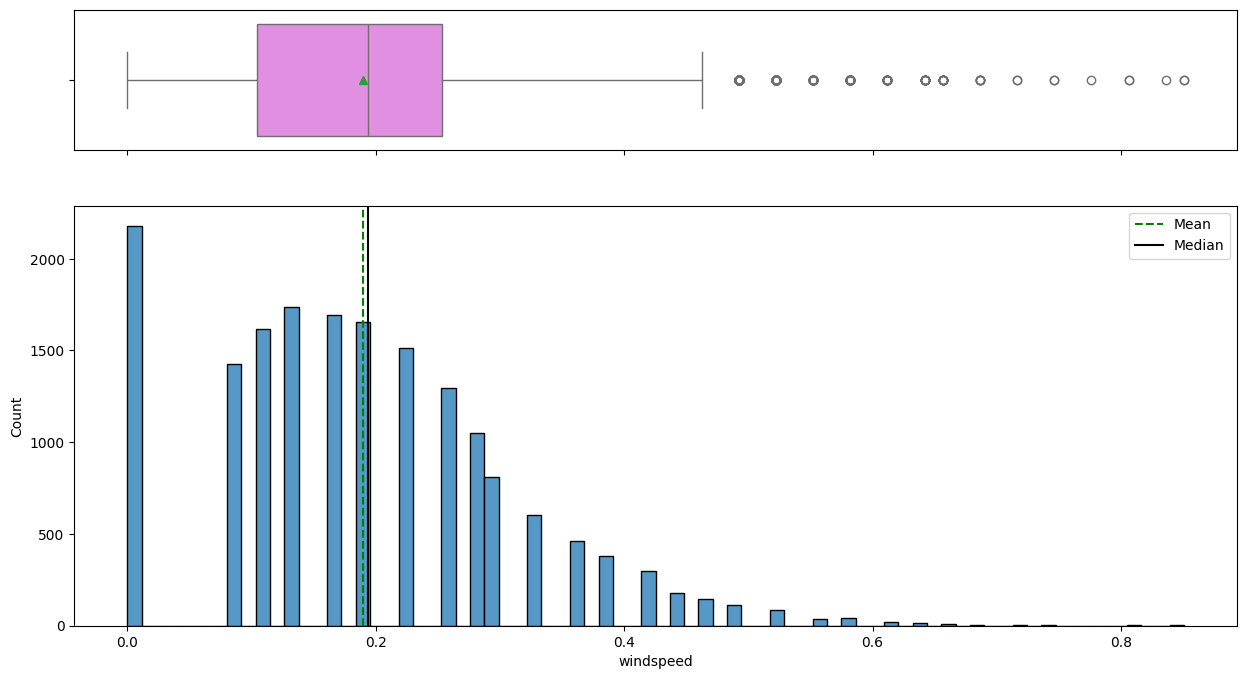

In [ ]:
histogram_boxplot(df, "windspeed")

- Wind speed has a right-skewed distribution and 0 has the highest count among all observations
- Distribution is not symmetric but mean and median are approx equal with a value equal to 0.19
- There are many outliers in this variable

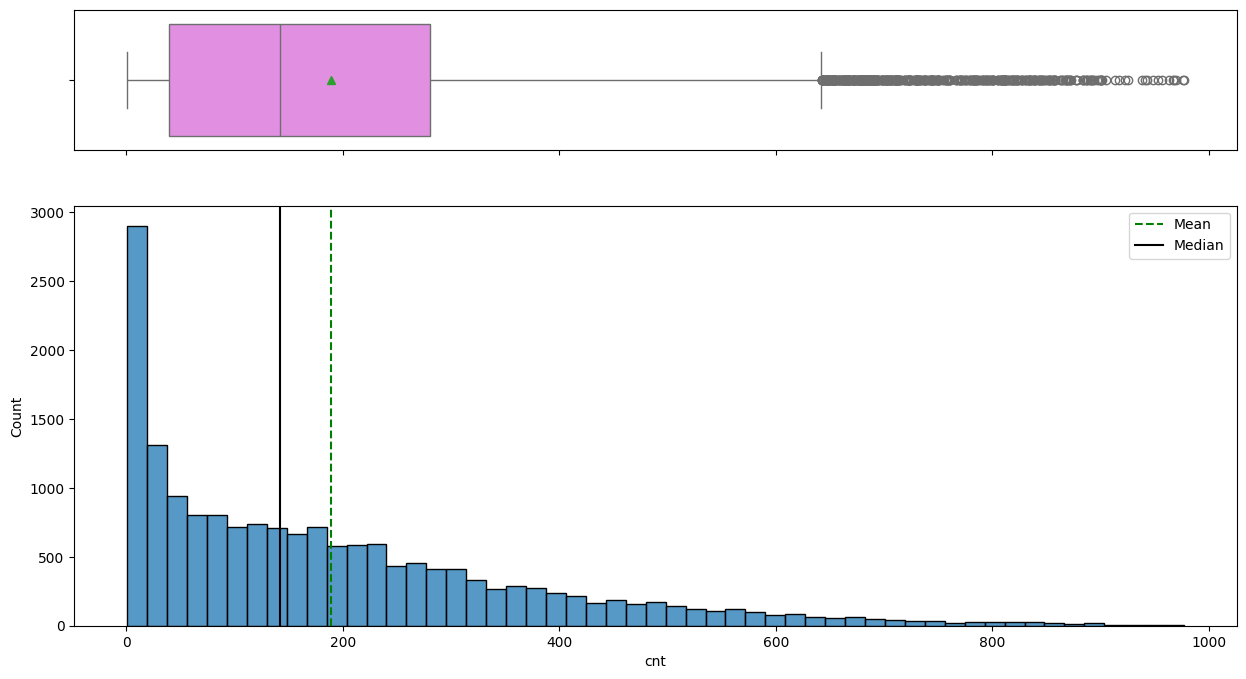

In [ ]:
histogram_boxplot(df, "cnt")

In [ ]:
# Top 5 highest values
df["cnt"].nlargest()

,cnt
14773,977
14964,976
14748,970
14725,968
15084,967


- The target variable i.e. the count of bikes rented has a right-skewed distribution
- The range of values is very large with many observations being less than 10 counts and some being greater than 900 count
- As evident from the boxplot, there are many outliers

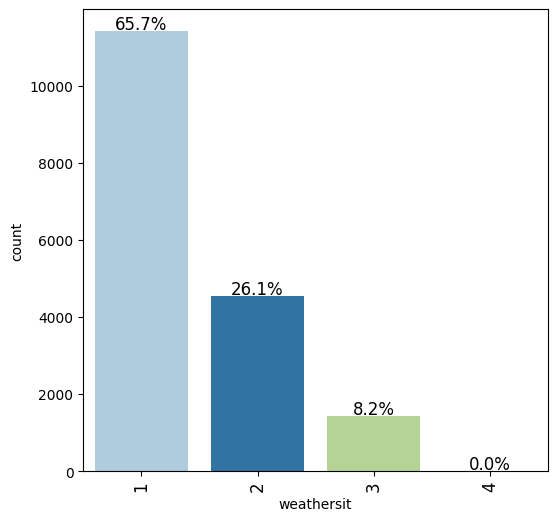

In [ ]:
labeled_barplot(df, "weathersit", perc = True)

- Season 1 has the highest percentage of observations i.e. 65.7%
- Season 2 and season 3 have 26.1% and 8.2% observations respectively
- We saw earlier that season 4 has only 3 observations in the data. Here, it shows 0% observations due to rounding off.

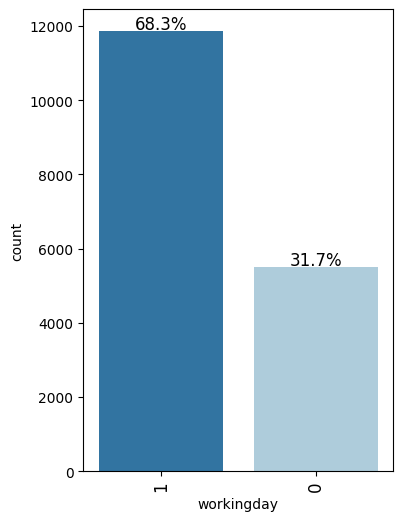

In [ ]:
labeled_barplot(df, "workingday", perc = True)

- As expected, the number of observations for working days is higher than the number of observations for non-working days.
- There are approx 68% observations for working days and 32% observations for non-working days.

## **Bivariate Analysis**

### **Correlation Check**

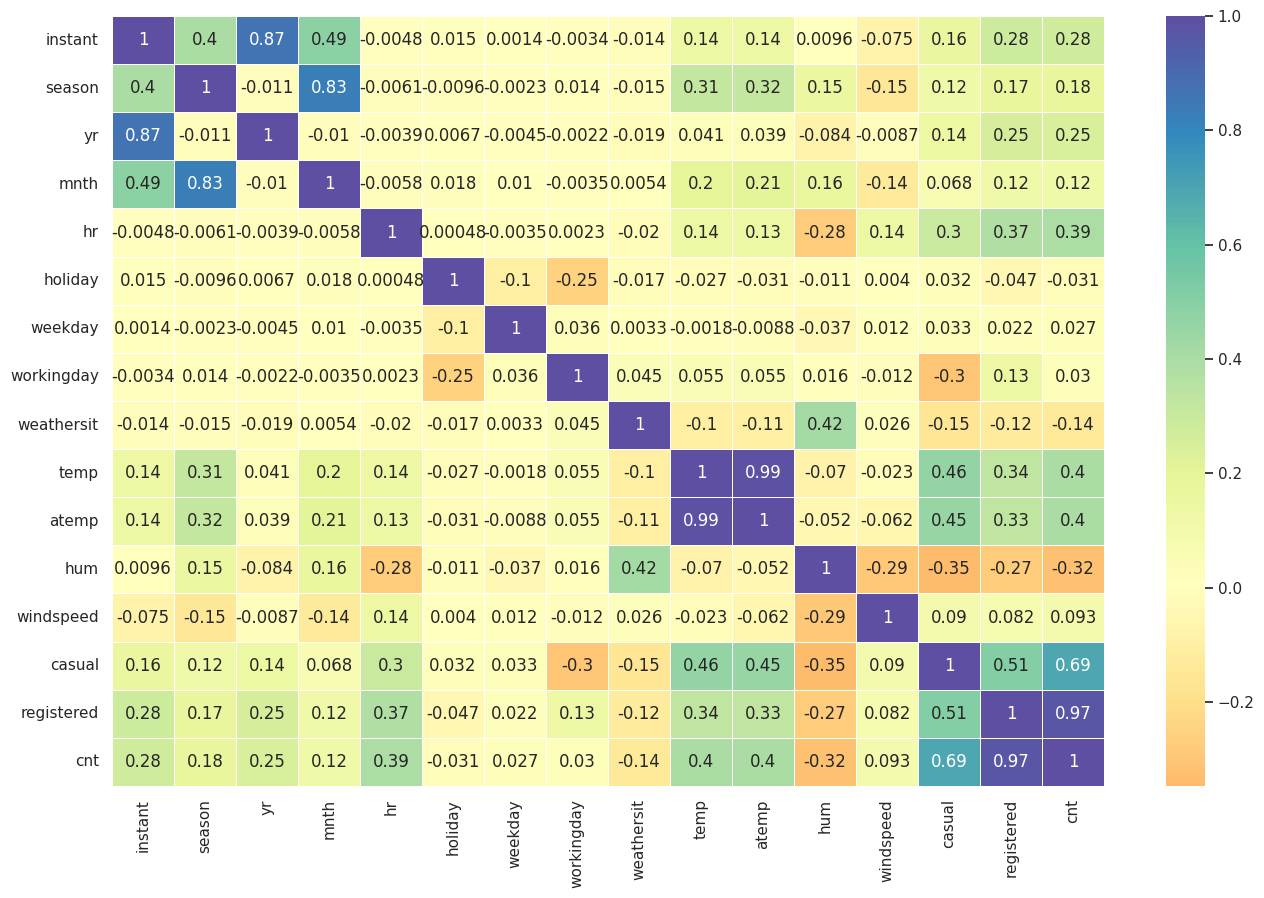

In [ ]:
sns.set(rc={"figure.figsize":(16,10)})
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            linewidths=.5,
            center=False,
            cmap="Spectral")
plt.show()

- We can see that temperature and feel like temperature are almost perfectly correlated
- Month and season have a high positive correlation among them
- As count is the addition of two columns - Casual and registered. We can drop these two columns because if we have casual and registered count then making a model won't make sense as we can simply add them. We would not have these 2 columns while predicting new observations

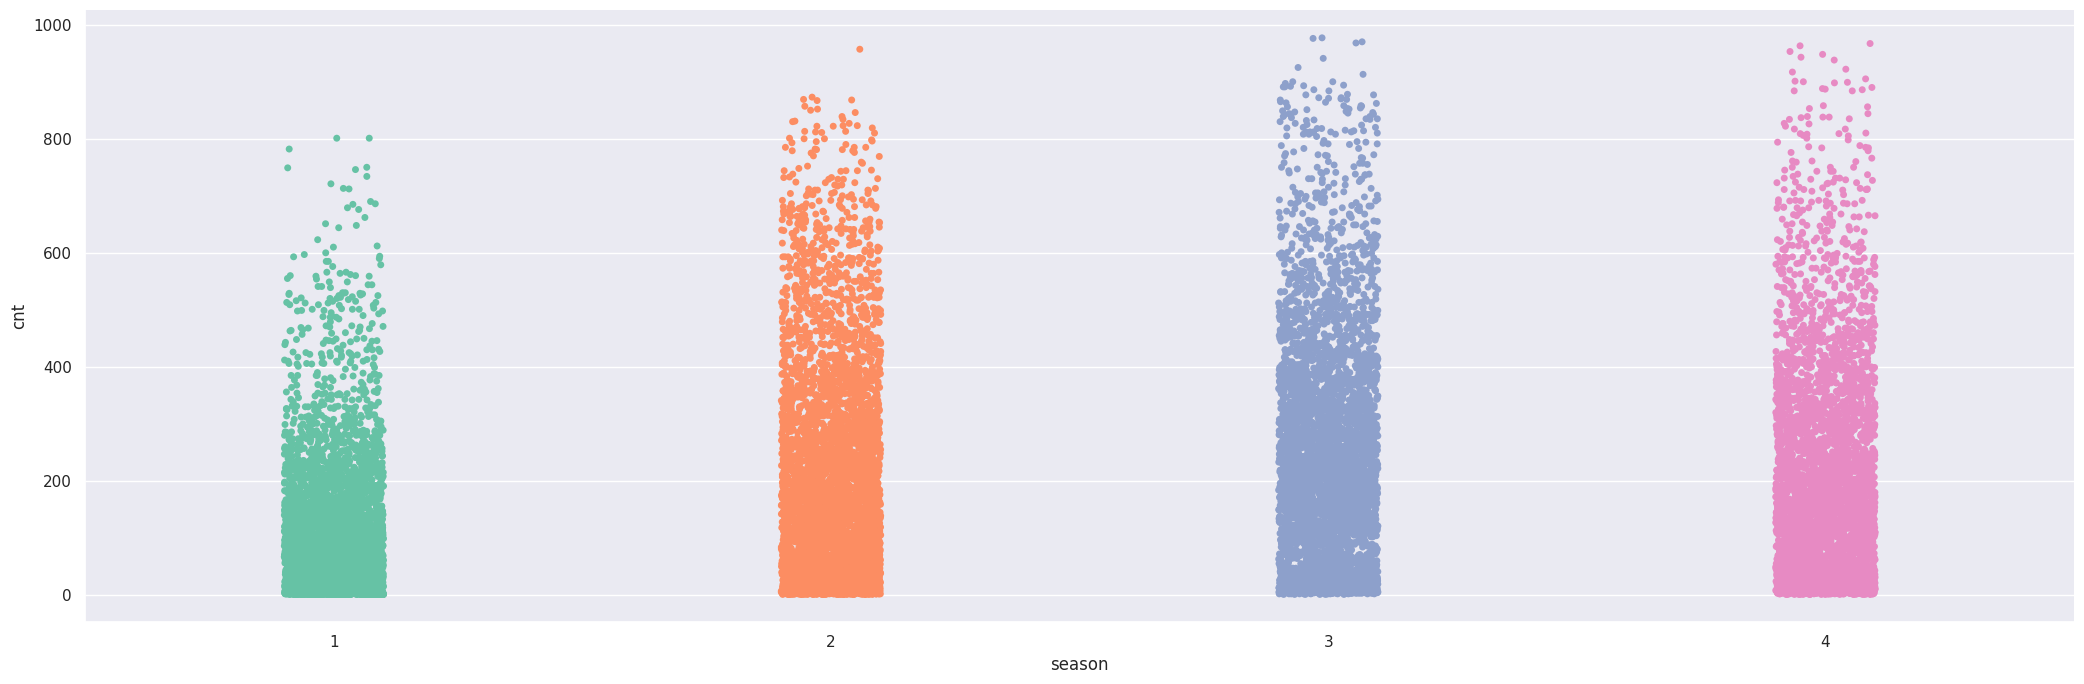

In [ ]:
sns.set(rc={"figure.figsize":(21,7)})
sns.catplot(x=df_hour["season"], y=df_hour["cnt"], palette="Set2", kind="strip", height=7, aspect=3);


- The lowest number of bikes are rented in the first season
- The highest number of bikes are shared in 3rd season
- This can be due to the relatively high temperature in season 1 i.e. spring as compared to season 3 i.e. fall

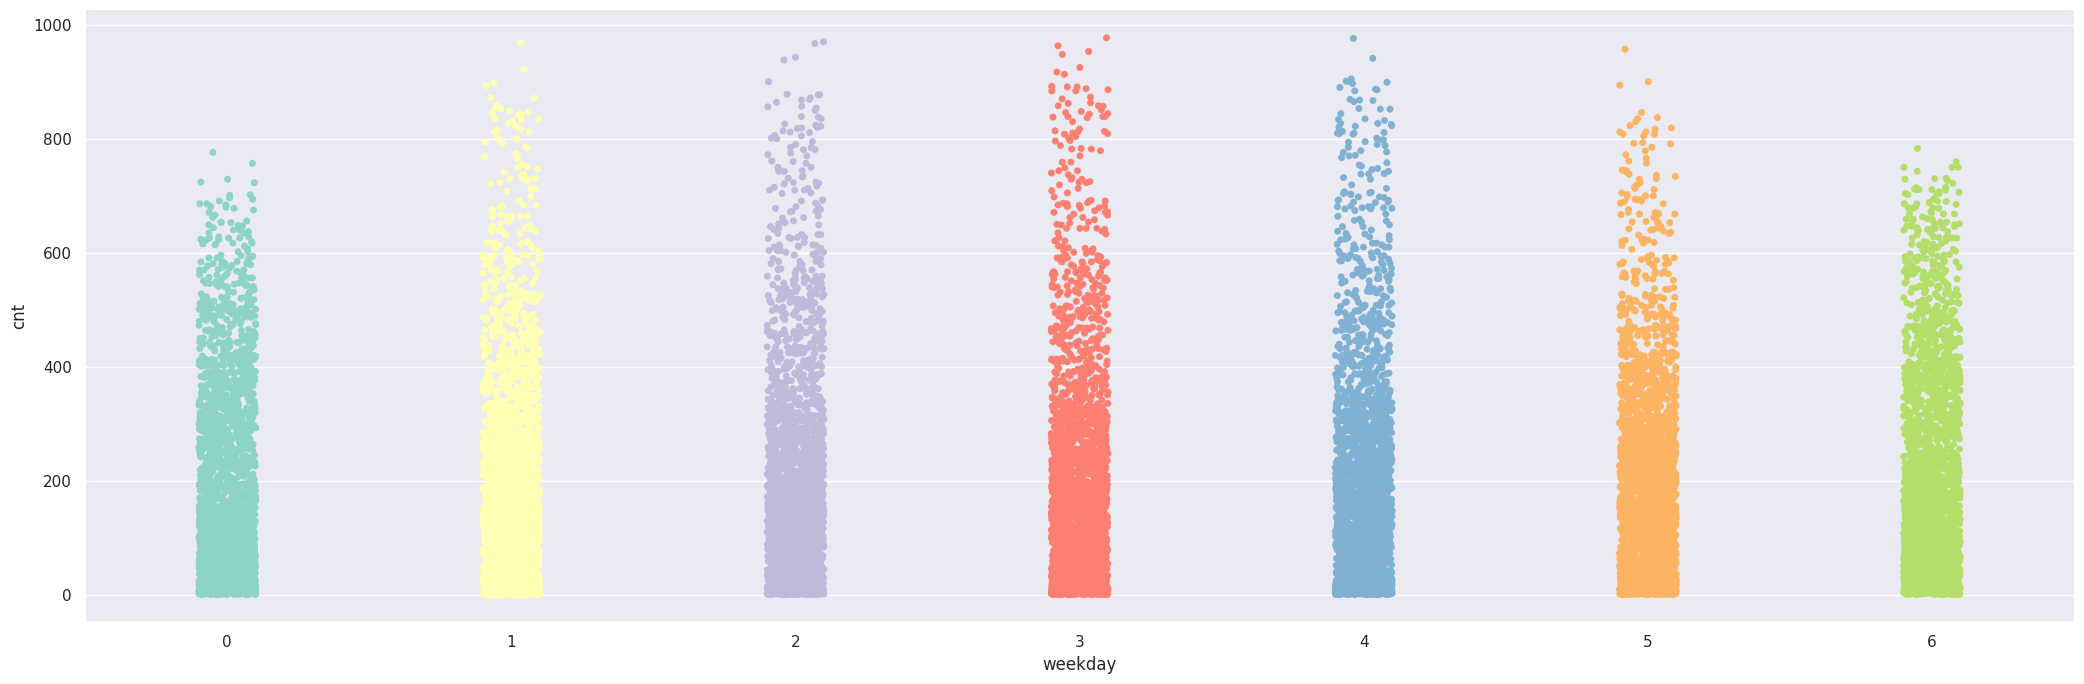

In [ ]:
sns.set(rc={"figure.figsize":(21,7)})
sns.catplot(x=df_hour["weekday"], y=df_hour["cnt"], palette="Set3", kind="strip", height=7, aspect=3);

- Weekends i.e. weekday=0 and weekday=6 have a low count of bikes rented and it is less varying.
- Working days have a higher count of bikes rented and have more variation in the count and there are some outliers for days from 1 to 5.
- This can be due to closed schools/offices on weekends.

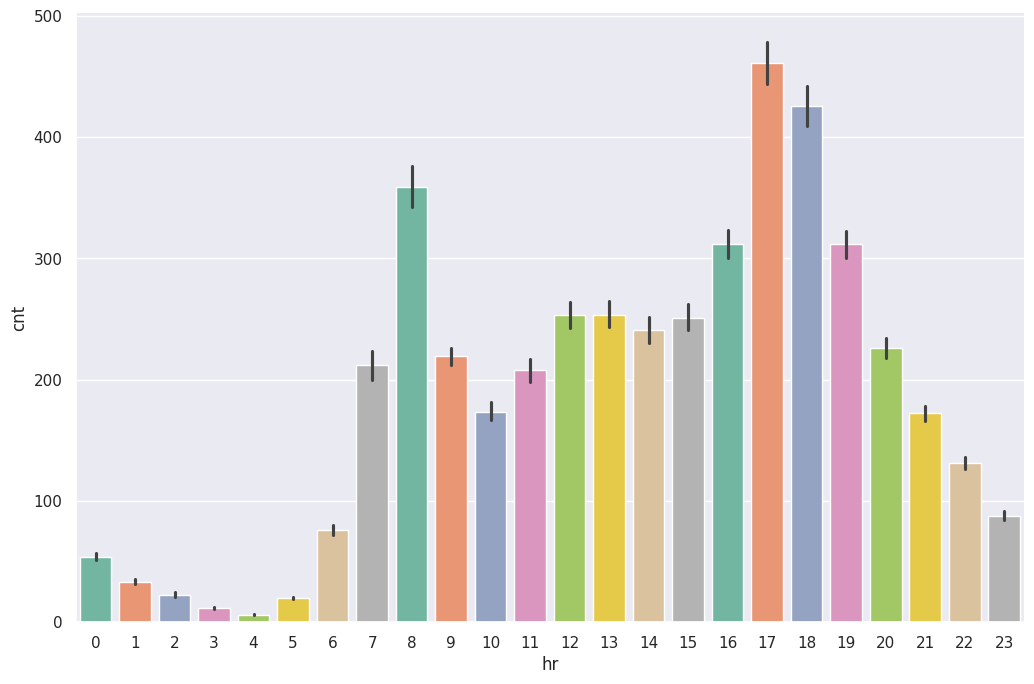

In [ ]:
sns.catplot(x=df_hour["hr"], y=df_hour["cnt"], kind="bar", palette="Set2", height=7, aspect=1.5, estimator=np.mean);

- We can see the average number of bikes rented is high at 8 AM and 5-6 PM, this can be due to office/school/college timings.
- The average number of bikes rented is very low for night time i.e. 12 AM to 5 AM.

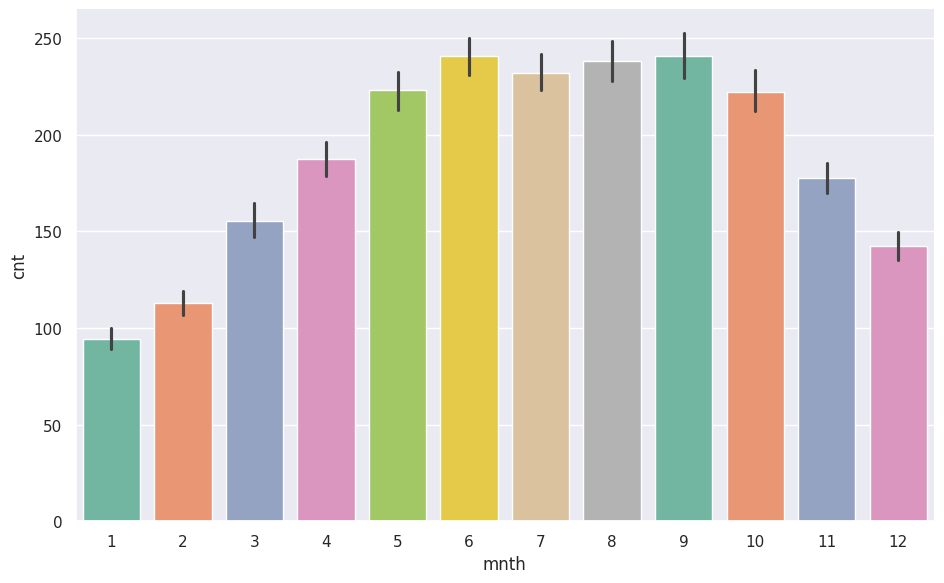

In [ ]:
sns.catplot(x=df_hour["mnth"], y=df_hour["cnt"], kind="bar", palette="Set2", height=6, aspect=1.6, estimator=np.mean);

- The average number of bikes rented is low for months - December, January, February. This can be due to the cold weather in these months.
- The average number of bikes rented is consistently high for months from May to October.

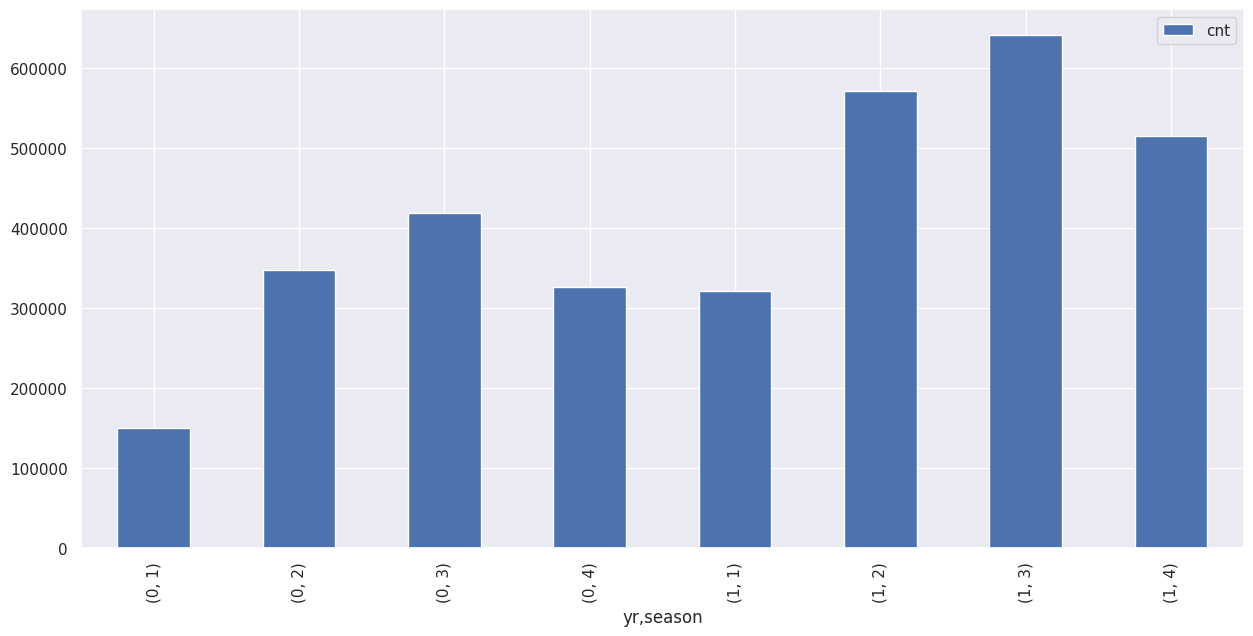

In [ ]:
sns.set(rc={"figure.figsize":(15,7)})
pd.pivot_table(data=df_hour, index=["yr", "season"], values="cnt", aggfunc=np.sum).plot(kind="bar");

- We can see that number of bikes rented is higher in the year 2012 for each season as compared to seasons in 2011.
- This shows that bike-sharing is becoming more popular with time.

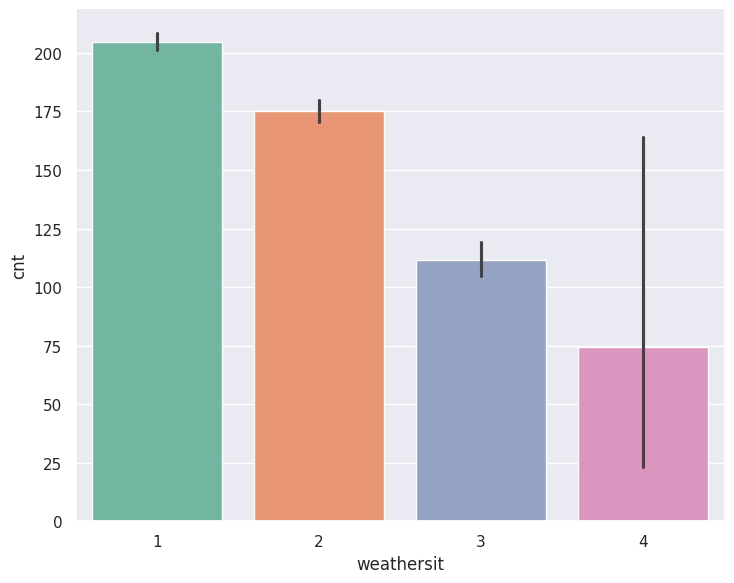

In [ ]:
sns.catplot(x=df_hour["weathersit"], y=df_hour["cnt"], palette="Set2",kind="bar", height=6, aspect=1.25, estimator=np.mean);

- As expected, the average count of bikes rented is much higher on clear or partly cloudy days compared to snowy or rainy days.
- This implies that the average count of bikes rented is hugely affected by the weather.

## **Data Preprocessing**

### **Outlier Detection and Treatment**

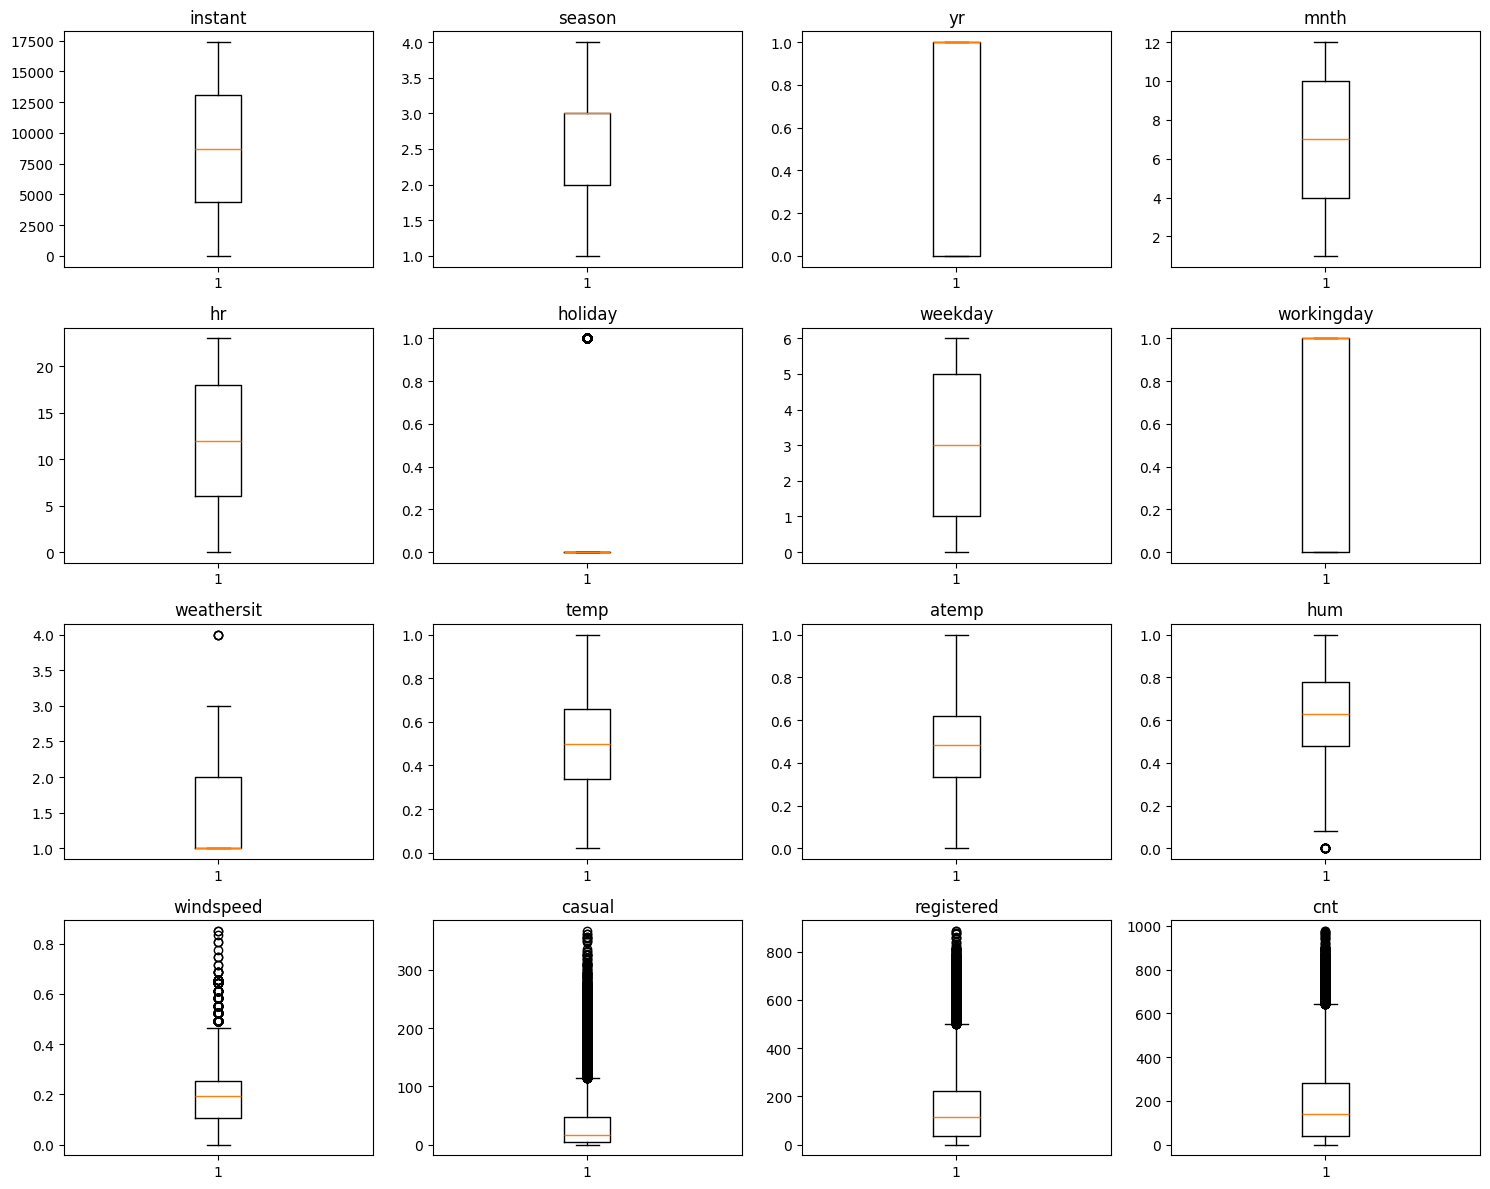

In [ ]:
# Get all numeric columns
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

# Set overall figure size
plt.figure(figsize=(15, 12))

# Loop through each numeric column
for i, variable in enumerate(numeric_columns):
  #Create a 4x4 grid for subplots
  plt.subplot(4, 4, i + 1)

  # Draw bocplot to detect outliers
  plt.boxplot(df[variable], whis=1.5)

  # set column name as title
  plt.title(variable)

# Fix spacing between plots
plt.tight_layout()

# Show the final graphs
plt.show()

- There are quite a few outliers in the data.
- However, we will not treat them as they are proper values.

**Actions for data pre-processing:**

* As count is the addition of two columns - Casual and registered, we can drop these two columns because if we have casual and registered count then making a model won't make sense as we can simply add them.

* We would not have these 2 columns while predicting new observations

In [20]:
# Dropping columns - casual and registered
df_hour.drop(columns=["casual", "registered"], inplace=True)

## **Data Preparataion for model building**

In [21]:
# Separating features and the target column
X = df_hour.drop("cnt", axis = 1)
y = df_hour["cnt"]

In [22]:
# Splitting the data info train and test sets in 70:30 tario
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=1, shuffle=True)

In [23]:
print("X_Train-Shape = ",X_train.shape)
print("X_Test-Shape = ",X_test.shape)

X_Train-Shape =  (12165, 12)
X_Test-Shape =  (5214, 12)


- We have 12,165 observations in the train set and 5,214 observations in the test set.

## **Bagging-Model Building and Hyperparameter Tynning**

- We will train different machine learning models on our data to see how well they perform initially.

- We will improve their performance by tweaking their internal settings (which are called hyperparameters).

- We will use a tool called `GridSearchCV` to automatically test different settings and pick the best one based on the highest `r2_score`.

- `R-squared` (Coefficient of Determination) is just our grading system for this regression model. It simply tells us what percentage of the target variable can be accurately predicted by our input features.

- Before we begin, we will write a single custom function to calculate and print these model scores, so we don't have to write the same code again and again.

In [24]:
# Function to compute Adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
  r2 = r2_score(targets, predictions)
  n = predictors.shape[0]
  k = predictors.shape[1]  # n=rows, k=cols
  return 1 - ((1 - r2) * (n - 1) / (n - k - 1))

# function to compute MAPE
def mape_score(targets, predictions):
  return np.mean(np.abs((targets - predictions) / y)) * 100

# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictions, targets):
  pred = model.predict(predictions)  # Make predictions

  r2 = r2_score(targets, pred)  # to compute R-squared
  adjr2 = adj_r2_score(predictions, targets, pred)  # to compute adjusted
  rmse = np.sqrt(mean_squared_error(targets, pred))  # to compute RMSE
  mae = mean_absolute_error(targets, pred)  # to compute MAE
  mape = mape_score(targets, pred)   # to compute MAPE

  # Calculate and return all metrics directly
  df_pref = pd.DataFrame(
      {
          "RMSE": rmse,
          "MAE": mae,
          "R-squared": r2,
          "Adj. R-squared": adjr2,
          "MAPE": mape,
      },
      index=[0],
  )

  return df_pref

In [25]:
## Function to calculate r2_score and RMSE on train and test data
def get_model_score(model, flag=True):
  '''
  model : classifier to predict values of X
  '''

  # deffining an empty list to store train and test results
  score_list = []

  pred_train = model.predict(X_train)
  pred_test = model.predict(X_test)

  train_r2 = metrics.r2_score(y_train, pred_train)
  test_r2 = metrics.r2_score(y_test, pred_test)
  train_rmse = np.sqrt(metrics.mean_squared_error(y_train, pred_train))
  test_rmse = np.sqrt(metrics.mean_squared_error(y_test, pred_test))

  # Adding all scores in the list
  score_list.extend((train_r2, test_r2, train_rmse, test_rmse))

  # If the flag is set to True then only the following print statements will be displayed, the default value is True
  if flag == True:
    print("R-square on training set : ", metrics.r2_score(y_train, pred_train))
    print("R-square on test set : ", metrics.r2_score(y_test, pred_test))
    print("RMSE on training set : ", np.sqrt(metrics.mean_squared_error(y_train, pred_train)))
    print("RMSE on test set : ", np.sqrt(metrics.mean_squared_error(y_test, pred_test)))

    # returning the list with train and test scores
    return score_list

### Decision Tree Model

In [26]:
d_tree = DecisionTreeRegressor(random_state = 1)
d_tree.fit(X_train, y_train)

DecisionTreeRegressor(random_state=1)

In [27]:
d_tree_model_train_perf = model_performance_regression(d_tree, X_train, y_train)
print("Training performance \n", d_tree_model_train_perf)

Training performance 
        RMSE       MAE  R-squared  Adj. R-squared      MAPE
0  0.442409  0.005754   0.999994        0.999994  0.004256


In [28]:
d_tree_model_test_perf = model_performance_regression(d_tree, X_test, y_test)
print("Testing performance \n", d_tree_model_test_perf)

Testing performance 
         RMSE        MAE  R-squared  Adj. R-squared      MAPE
0  60.827833  35.107787   0.892227        0.891979  38.03325


- The Decision tree model with default parameters is overfitting the train data.
- Let's see if we can reduce overfitting and improve performance on test data by tuning hyperparameters.

### Hyperparameter Tunning

In [31]:
# Choose the type of classifier
dtree_tuned = DecisionTreeRegressor(random_state = 1)

# Grid of parameters to choose from
parameters = {"max_dept" : list(np.arange(2,20)) + [None],
              "min_samples_leaf" : [1, 3, 5, 7, 10],
              ",max_leaf_nodes" : [2, 3, 5, 10, 15] + [None],
              "min_impurity_decrease" : [0.001, 0.01, 0.1, 0.0]
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the Grid search
grid_obj = GridSearchCV(dtree_tuned, parameters, scoring=scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
dtree_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data
dtree_tuned.fit(X_train, y_train)

In [32]:
dtree_tuned_model_train_perf = model_performance_regression(dtree_tuned, X_train, y_train)
print("Training performance \n", dtree_tuned_model_train_perf)

Training performance 
         RMSE        MAE  R-squared  Adj. R-squared       MAPE
0  36.442792  22.525337   0.958856        0.958816  28.657314


In [33]:
dtree_tuned_model_test_perf = model_performance_regression(dtree_tuned, X_test, y_test)
print("Testing performance \n", dtree_tuned_model_test_perf)

Testing performance 
         RMSE        MAE  R-squared  Adj. R-squared       MAPE
0  54.969957  31.841364   0.911985        0.911782  38.356397


- The overfitting is reduced after hyperparameter tuning and the test score has increased by approx 2%.
- RMSE is also reduced on test data and the model is generalizing better than the decision tree model with default parameters.

**Plotting the feature importance of each variable**

In [34]:
print(pd.DataFrame(dtree_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

                 Imp
hr          0.634942
temp        0.117441
yr          0.079271
workingday  0.063920
season      0.022164
atemp       0.019463
weathersit  0.019460
hum         0.017227
mnth        0.010498
weekday     0.010009
windspeed   0.003882
holiday     0.001724


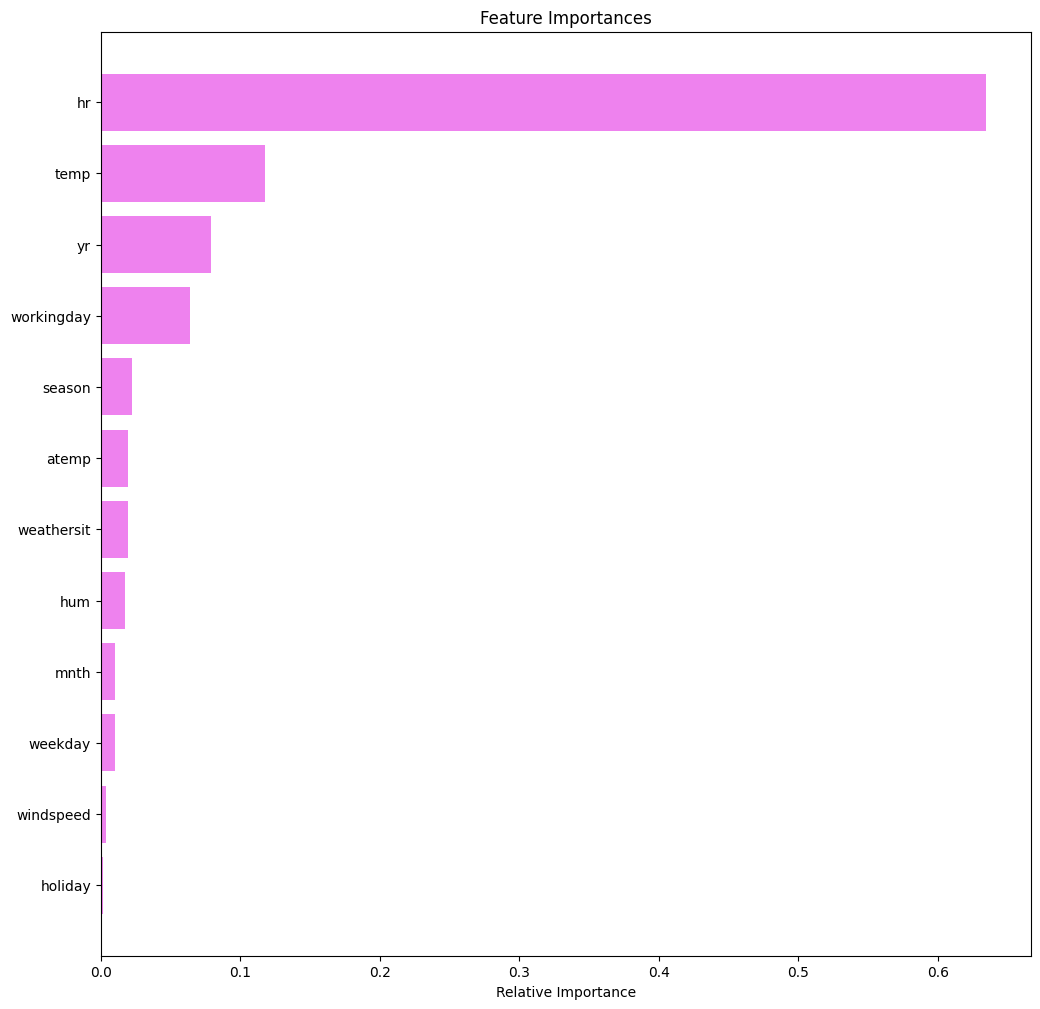

In [36]:
feature_names = X_train.columns
importances = dtree_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize = (12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color = "violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

- hr is the most important feature, in addition to temp and yr, for tuned decision tree model

## Random Forest Model

In [37]:
rf_estimator = RandomForestRegressor(random_state = 1)
rf_estimator.fit(X_train, y_train)

RandomForestRegressor(random_state=1)

In [38]:
rf_estimator_model_train_perf = model_performance_regression(rf_estimator, X_train, y_train)
print("Training performance \n", rf_estimator_model_train_perf)

Training performance 
         RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  16.167421  9.641324   0.991902        0.991894  11.757327


In [39]:
rf_estimator_model_test_perf = model_performance_regression(rf_estimator, X_test, y_test)
print("Testing performance \n", rf_estimator_model_test_perf)

Testing performance 
        RMSE        MAE  R-squared  Adj. R-squared       MAPE
0  44.56215  26.192368   0.942159        0.942026  32.748634


- Random forest is giving a good r2 score of 94% on the test data but it is slightly overfitting the train data.
- Let's try to reduce this overfitting by hyperparameter tuning.

## Hyperparameter Tuning

In [40]:
# Choose the type of classifier.
rf_tuned = RandomForestRegressor(random_state=1)

# Grid of parameters to choose from
parameters = {
                'max_depth':[4, 6, 8, 10, None],
                'max_features': ['sqrt','log2',None],
                'n_estimators': [80, 90, 100, 110, 120]
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(rf_tuned, parameters, scoring=scorer,cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
rf_tuned.fit(X_train, y_train)

RandomForestRegressor(max_features=None, n_estimators=120, random_state=1)

In [41]:
rf_tuned_model_train_perf = model_performance_regression(rf_tuned, X_train, y_train)
print("Training performance \n", rf_tuned_model_train_perf)

Training performance 
         RMSE       MAE  R-squared  Adj. R-squared      MAPE
0  16.160093  9.622604    0.99191        0.991902  11.73432


In [42]:
rf_tuned_model_test_perf = model_performance_regression(rf_tuned, X_test, y_test)
print("Testing performance \n", rf_tuned_model_test_perf)

Testing performance 
       RMSE        MAE  R-squared  Adj. R-squared       MAPE
0  44.5806  26.202363   0.942111        0.941977  32.734172


- No significant change in the result. The result is almost the same before or after the hyperparameter tuning.

In [43]:
print(pd.DataFrame(rf_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

                 Imp
hr          0.610116
temp        0.121773
yr          0.076295
workingday  0.059489
hum         0.026844
weathersit  0.020962
season      0.020876
atemp       0.020670
mnth        0.016153
weekday     0.013539
windspeed   0.010510
holiday     0.002774


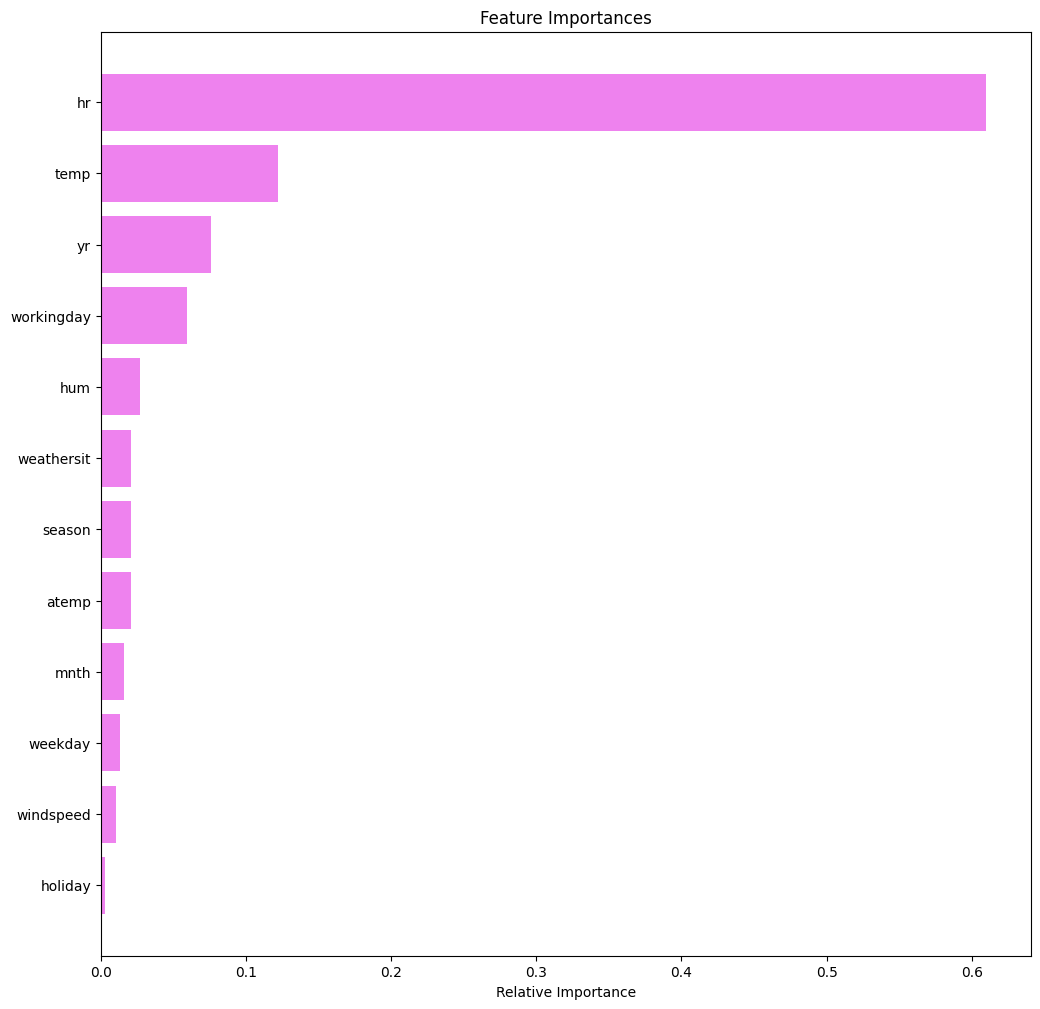

In [44]:
feature_names = X_train.columns
importances = rf_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize = (12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

- hr is the most important feature, in addition to temp and yr, for the tuned random forest model.


## Boosting - Model Building and Hyperparameter Tuning

### AdaBoost Regressor

In [45]:
ad_regressor = AdaBoostRegressor(random_state=1)
ad_regressor.fit(X_train, y_train)

AdaBoostRegressor(random_state=1)

In [46]:
ad_regressor_model_train_perf = model_performance_regression(ad_regressor, X_train, y_train)
print("Training performance \n", ad_regressor_model_train_perf)

Training performance 
          RMSE        MAE  R-squared  Adj. R-squared        MAPE
0  104.441843  80.996029   0.662067        0.661733  185.877344


In [47]:
ad_regressor_model_test_perf = model_performance_regression(ad_regressor, X_test, y_test)
print("Testing performance \n", ad_regressor_model_test_perf)

Testing performance 
          RMSE        MAE  R-squared  Adj. R-squared        MAPE
0  105.415729  81.468364   0.676321        0.675574  196.403082


- AdaBoost is generalizing well but it is giving poor performance, in terms of r2 score as well as RMSE, as compared to the decision tree and random forest model.

### Hyperparameter Tuning

In [48]:
# Choose the type of classifier.
ab_tuned = AdaBoostRegressor(random_state=1)

# Grid of parameters to choose from
parameters = {'n_estimators': np.arange(10,100,10),
              'learning_rate': [1, 0.1, 0.5, 0.01],
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(ab_tuned, parameters, scoring=scorer,cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
ab_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
ab_tuned.fit(X_train, y_train)

AdaBoostRegressor(learning_rate=1, n_estimators=np.int64(30), random_state=1)

In [49]:
ab_tuned_model_train_perf = model_performance_regression(ab_tuned, X_train, y_train)
print("Training performance \n", ab_tuned_model_train_perf)

Training performance 
          RMSE        MAE  R-squared  Adj. R-squared        MAPE
0  103.326379  80.468809   0.669247         0.66892  195.189129


In [50]:
ad_tuned_model_test_perf = model_performance_regression(ab_tuned, X_test, y_test)
print("Testing performance \n", ad_tuned_model_test_perf)

Testing performance 
          RMSE        MAE  R-squared  Adj. R-squared        MAPE
0  104.430458  81.015165   0.682343         0.68161  207.467888


- We can see that there is no significant improvement in the model after hyperparameter tuning.

In [51]:
# importance of features in the tree building
print(pd.DataFrame(ab_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

                 Imp
hr          0.523674
yr          0.135837
atemp       0.076841
workingday  0.058274
season      0.049087
weathersit  0.047040
hum         0.046359
mnth        0.036370
temp        0.026518
weekday     0.000000
holiday     0.000000
windspeed   0.000000


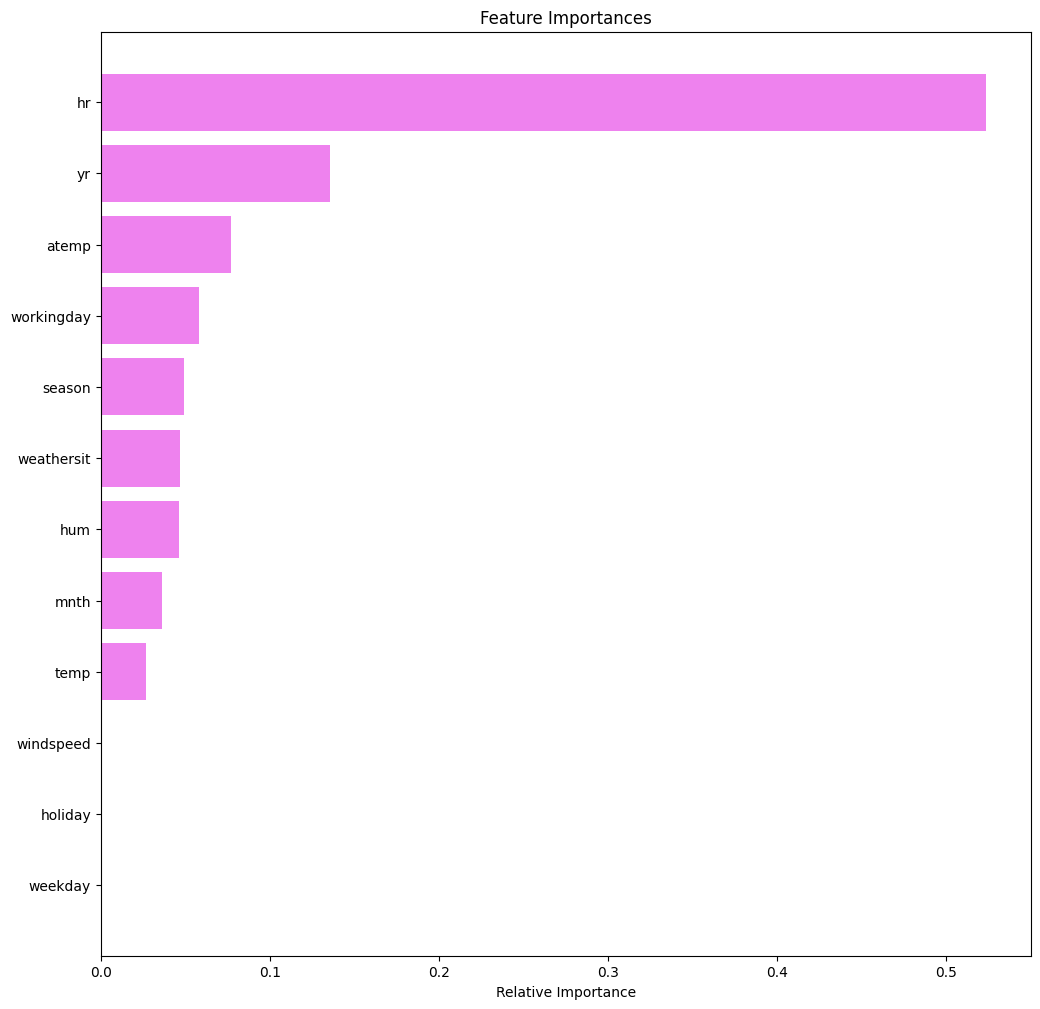

In [52]:
feature_names = X_train.columns
importances = ab_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize = (12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

- hr is the most important feature here, followed by yr and atemp.

### Gradient Boosting Regressor

In [53]:
gb_estimator = GradientBoostingRegressor(random_state=1)
gb_estimator.fit(X_train, y_train)

GradientBoostingRegressor(random_state=1)

In [55]:
gb_estimator_model_train_perf = model_performance_regression(gb_estimator, X_train, y_train)
print("Training performance \n", gb_estimator_model_train_perf)

Training performance 
        RMSE        MAE  R-squared  Adj. R-squared       MAPE
0  71.87459  48.518039   0.839959        0.839801  92.152544


In [57]:
gb_estimator_model_test_perf = model_performance_regression(gb_estimator, X_test, y_test)
print("Testing performance \n", gb_estimator_model_test_perf)

Testing performance 
         RMSE        MAE  R-squared  Adj. R-squared        MAPE
0  74.173279  49.691124    0.83975         0.83938  100.149788


- Gradient boosting is generalizing well and giving decent results but not as good as random forest.

### Hyperparameter Tuning

In [ ]:
# Choose the type of classifier.
gb_tuned = GradientBoostingRegressor(random_state=1)

# Grid of parameters to choose from
parameters = {'n_estimators': np.arange(50,200,25),
              'subsample':[0.7,0.8,0.9,1],
              'max_features':[0.7,0.8,0.9,1],
              'max_depth':[3,5,7,10]
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(gb_tuned, parameters, scoring=scorer,cv=5,n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
gb_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
gb_tuned.fit(X_train, y_train)

In [ ]:
gb_tuned_model_train_perf = model_performance_regression(gb_tuned, X_train, y_train)
print("Training performance \n", gb_tuned_model_train_perf)

In [ ]:
gb_tuned_model_test_perf = model_performance_regression(gb_tuned, X_test, y_test)
print("Testing performance \n", gb_tuned_model_test_perf)

- We can see that the model has improved significantly in terms of r2 score and RMSE.
- The r2 score has increased by approx 12% on the test data.
- RMSE has decreased by more than 30 for the test data.

In [ ]:
# importance of features in the tree building
print(pd.DataFrame(gb_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

In [ ]:
feature_names = X_train.columns
importances = gb_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

- hr is the most important feature
- temp, yr and workingday have almost equal importance

### AGBoost Regressor

In [ ]:
xgb_estimator = XGBRegressor(random_state=1, verbosity = 0)
xgb_estimator.fit(X_train, y_train)

In [ ]:
xgb_estimator_model_train_perf = model_performance_regression(xgb_estimator, X_train, y_train)
print("Training performance \n",xgb_estimator_model_train_perf)

In [ ]:
xgb_estimator_model_test_perf = model_performance_regression(xgb_estimator, X_test,y_test)
print("Testing performance \n",xgb_estimator_model_test_perf)

- XGBoost with default parameters is giving almost as good results as the tuned gradient boosting model.

### Hyperparameter Tuning

In [ ]:
# Choose the type of classifier.
xgb_tuned = XGBRegressor(random_state=1, verbosity = 0)

# Grid of parameters to choose from
parameters = {'n_estimators': [75,100,125,150],
              'subsample':[0.7, 0.8, 0.9, 1],
              'gamma':[0, 1, 3, 5],
              'colsample_bytree':[0.7, 0.8, 0.9, 1],
              'colsample_bylevel':[0.7, 0.8, 0.9, 1]
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(xgb_tuned, parameters, scoring=scorer,cv=5,n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
xgb_tuned.fit(X_train, y_train)

In [ ]:
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
print("Training performance \n",xgb_tuned_model_train_perf)

In [ ]:
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
print("Training performance \n",xgb_tuned_model_train_perf)

In [ ]:
# importance of features in the tree building
print(pd.DataFrame(xgb_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

In [ ]:
feature_names = X_train.columns
importances = xgb_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

- In XGBoost, workingday is the most important feature followed by features - hr and yr



## Comparing all models

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [d_tree_model_train_perf.T, dtree_tuned_model_train_perf.T, rf_estimator_model_train_perf.T,rf_tuned_model_train_perf.T,
    ad_regressor_model_train_perf.T,ab_tuned_model_train_perf.T,gb_estimator_model_train_perf.T,gb_tuned_model_train_perf.T,
    xgb_estimator_model_train_perf.T,xgb_tuned_model_train_perf.T],
    axis=1,
)

models_train_comp_df.columns = [
    "Decision Tree",
    "Decision Tree Tuned",
    "Random Forest Estimator",
    "Random Forest Tuned",
    "Adaboost Regressor",
    "Adaboost Tuned",
    "Gradient Boost Estimator",
    "Gradient Boost Tuned",
    "XGB",
    "XGB Tuned"
]

print("Training performance comparison:")
models_train_comp_df

In [ ]:
# Testing performance comparison

models_test_comp_df = pd.concat(
    [dtree_model_test_perf.T, dtree_tuned_model_test_perf.T, rf_estimator_model_test_perf.T,rf_tuned_model_test_perf.T,
    ab_regressor_model_test_perf.T,ab_tuned_model_test_perf.T,gb_estimator_model_test_perf.T,gb_tuned_model_test_perf.T,
    xgb_estimator_model_test_perf.T,xgb_tuned_model_test_perf.T],
    axis=1,
)

models_test_comp_df.columns = [
    "Decision Tree",
    "Decision Tree Tuned",
    "Random Forest Estimator",
    "Random Forest Tuned",
    "Adaboost Regressor",
    "Adaboost Tuned",
    "Gradient Boost Estimator",
    "Gradient Boost Tuned",
    "XGB",
    "XGB Tuned"
]

print("Testing performance comparison:")
models_test_comp_df

- The tuned gradient boosting model is the best model here. It has the highest r2 score of approx 95.5% and the lowest RMSE of approx 39 on the test data.
- Gradient boosting and XGBoost are the top 2 models. They are all giving a similar performance.

In [ ]:
# So plot observed and predicted values of the test data for the best model i.e. tuned gradient boosting model
fig, ax = plt.subplots(figsize=(8, 6))
y_pred=gb_tuned.predict(X_test)
ax.scatter(y_test, y_pred, edgecolors=(0, 0, 1))
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=3)
ax.set_xlabel('Observed')
ax.set_ylabel('Predicted')
ax.set_title("Observed vs Predicted")
plt.grid()
plt.show()

- We can see that points are dense on the line where predicted is equal to the observed.
- This implies that most of the predicted values are close to the true values with some exceptions as seen in the plot.

## Conclusions and Business Recommendations

- We can use this predictive model for any season and environmental parameters (which we know in advance) and can predict the count of the bikes to be rented. The ability to predict the number of hourly users can allow the entities (businesses/governments) that oversee these systems to manage them more efficiently and cost-effectively.
- More bikes can be made available for the fall and winter seasons as the number of bikes rented is high in these seasons.
- As the number of bikes rented is high for day timings compared to night timings, similarly, fall and winter seasons have more surges compared to other seasons. We can choose differential prices of bikes accordingly.
- As most of the rentals are for commuting to workplaces and colleges daily, company can launch more stations near busy workplaces or schools/colleges to reach out to their main customers.
- Number of bikes rented is heavily dependent on the weather. So, we should adjust the number of available bikes in an area based on the weather forecast.
- Maintenance activities for bikes can be done at night due to low usage of bikes during the nighttime.
- Company can provide offers or coupons like a monthly subscription to compensate for the low count on holidays or weekends.